<h1>Musical Notation Generator</h1>
<h2>Data Analysis and Pre-processing</h2>
<h6>~Adam McWilliams</h6>
This notebook is responsible for generating a Keras deep learning model which is able to detect the pitch of a given musical sample.

## Section 0: Import Libraries

In [1]:
from scipy.io.wavfile import read
from collections import deque
from string import Template
from glob import glob
from tqdm import tqdm
import xml.etree.ElementTree as etree
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import wave
import os

## Section 1: Generate Annotations
This code is responsible for generating a .xml file which can reference the wave files downloaded from NSynth.<br>
The path variable should point to a directory containing wave files with the format:<br>
<code>instrumentName_instrumentSourceType_instrumentInt-pitch-velocity</code>

In [2]:
path = r'C:\Users\Adam\Documents\csc3002-40266924\Training\audio'
if os.path.isdir(path):
    foundAudioFiles = glob(os.path.join(path, '*'))
    fileNames = [os.path.basename(os.path.splitext(i)[0]) for i in foundAudioFiles]
    fileTypes = [os.path.splitext(i)[1] for i in foundAudioFiles]
else:
    print("Invalid Directory")

Each annotation within the xml file will follow this format. The data within the files is not stored here for better data management.

In [3]:
templateLabel = Template("""\t<$sample_name>
        <file>
            <filename>$filename</filename>
            <filetype>$filetype</filetype>
        </file>
        <sample>
            <sample_name>$sample_name</sample_name>
            <sample_rate>$sample_rate</sample_rate>
            <num_samples>$num_samples</num_samples>
        </sample>
        <features>
            <instrument_name>$instrument_name</instrument_name>
            <instrument_source>$instrument_source</instrument_source>
            <instrument>$instrument</instrument>
            <pitch>$pitch</pitch>
            <velocity>$velocity</velocity>
        </features>
    </$sample_name>\n""")

In [4]:
labelFileName = "labels"
outputFilePath = os.path.join(os.path.dirname(path), labelFileName)
if not outputFilePath.endswith('.xml'):
    outputFilePath = outputFilePath + '.xml'
    
if os.path.isfile(outputFilePath):
    print(f"File {outputFilePath}, already exists")
else:
    with open(outputFilePath, 'xt') as f:
        f.write('<root>\n')

This code will iterate through ever file in the path directory and generate an annotation for it and then append it to the labels xml file.

In [5]:
for i, file in enumerate(tqdm(foundAudioFiles)):
    if fileTypes[i] == '.wav':
        with wave.open(file, 'rb') as openFile:
            properties = openFile.getparams()
            
        if not fileNames[i].startswith('synth_lead'):
            instrumentName, instrumentSourceType, oth = fileNames[i].split('_')
            instrumentInt, pitch, velocity = oth.split('-')
        else:
            instrumentName, instrumentType, instrumentSourceType, oth = fileNames[i].split('_')
            instrumentInt, pitch, velocity = oth.split('-')
            instrumentName = f"{instrumentName}_{instrumentType}"
            
        thisSampleDict = {
            'filename': f"{fileNames[i]}{fileTypes[i]}",
            'sample_name': fileNames[i],
            'filetype': fileTypes[i],
            'instrument_name': instrumentName,
            'instrument_source': instrumentSourceType,
            'instrument': instrumentInt,
            'pitch': pitch,
            'velocity': velocity,
            'sample_rate': properties[2],
            'num_samples': properties[3]
        }
        with open(outputFilePath, 'at') as f:
            f.write(templateLabel.substitute(thisSampleDict))

with open(outputFilePath, 'at') as f:
    f.write('</root>')

100%|████████████████████████████████████████████████████████████████████████████| 4096/4096 [00:01<00:00, 2136.26it/s]


## Section 2: Analysing dataset
This 'labels.xml' file can be investigated to gather insight into the datasets.

In [6]:
features = ['instrument','pitch']
featureSet = dict.fromkeys(features)
counts = {}

tree = etree.parse(outputFilePath)

for feature in featureSet:
    thisFeatureList = [i.text for i in tree.iter(feature)]
    featureSet[feature] = thisFeatureList
    
    counts[feature] = {uniqueValue: thisFeatureList.count(uniqueValue) for uniqueValue in set(thisFeatureList)}

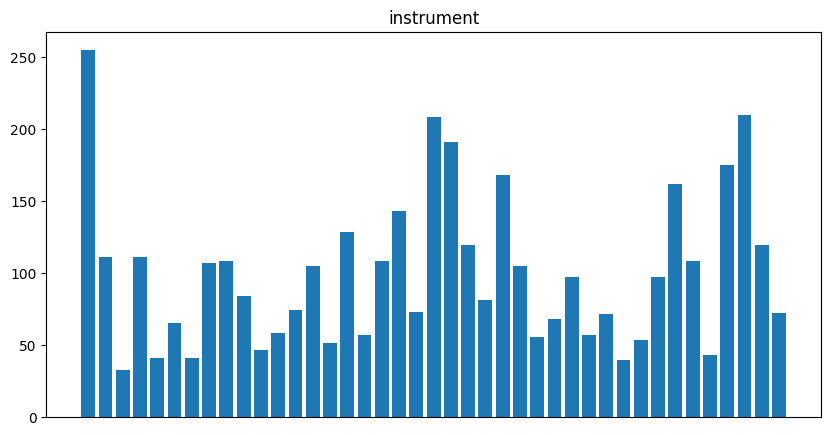

In [7]:
data = counts[features[0]]

plt.rcParams['figure.figsize'] = [10, 5]
plt.bar(range(len(data)), list(data.values()), align='center')
plt.xticks([])
plt.title(features[0])

plt.show()

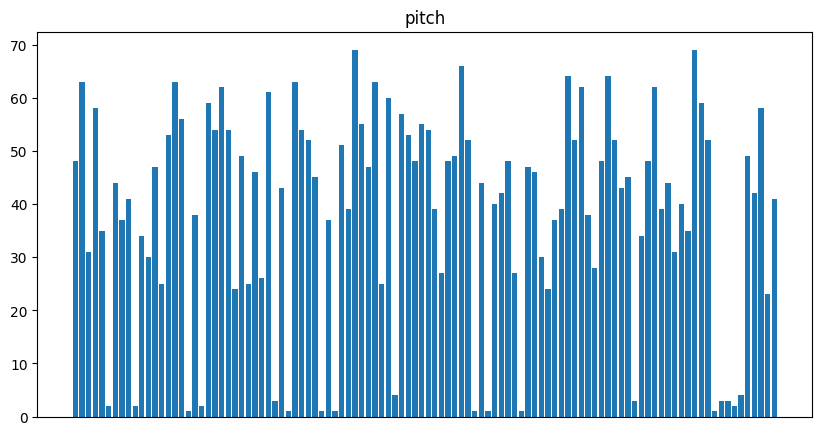

In [8]:
data = counts[features[1]]

plt.rcParams['figure.figsize'] = [10, 5]
plt.bar(range(len(data)), list(data.values()), align='center')
plt.xticks([])
plt.title(features[1])

plt.show()

## Section 3: Generating Spectrograms
These audio samples can now be used to investigate spectrogram creation.

In [9]:
def genSpec(samplePath):
    audioTensor = tf.convert_to_tensor(read(samplePath)[1])
    normalisedTensor = tf.squeeze(tf.cast(audioTensor, tf.float32) / 32768.0)
    spectrogram = tf.signal.stft(normalisedTensor[:10000], frame_length=256, frame_step=64)
    spectrogram = tf.abs(spectrogram)
    spectrogram = tf.expand_dims(spectrogram, axis=2)
    return tf.squeeze(spectrogram)

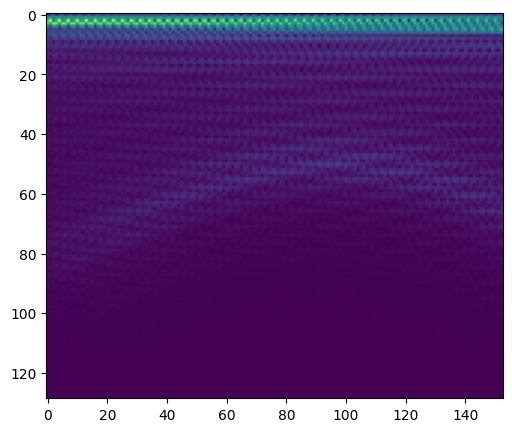

Resulting spectrogram is of size: [153 129] pixels


In [10]:
samplePath = foundAudioFiles[200]

plt.figure()
plt.imshow(tf.transpose(genSpec(samplePath)))
plt.show()
print(f"Resulting spectrogram is of size: {tf.transpose(genSpec(samplePath).shape)} pixels")

After generating a single spectrogram we are ready to convert the whole dataset

## Section 4: Batch Spectrograms
This cell will convert all the files we have annotated into a tfrecord dataset.

In [11]:
def generateSpectrograms(labelPath: str, sampleNames: list, labels=[], data=[]) -> (list, list):
    tree = etree.parse(labelPath)
    for sample in tqdm(sampleNames):
        pitchStr = tree.find(sample).find('features').find('pitch').text
        try:
            thisPitch = int(pitchStr)
        except ValueError:
            return -1

        samplePath = os.path.join(path, f'{sample}.wav')
        try:
            thisSpectrogram = genSpec(samplePath)
        except FileNotFoundError:
            return -2

        thisSpectrogram = tf.transpose(thisSpectrogram)
        data.append(thisSpectrogram)
        labels.append(thisPitch)
    return data, labels

If the number of audio files take up a significant amount of memory they can be split into smaller batches to run on loss powerful machinery.

In [12]:
batches = 1
batchedSamples = np.array_split(fileNames, batches)

try:
    os.mkdir("batches")
except FileExistsError:
    pass

for i, batch in enumerate(batchedSamples):
    data, labels = generateSpectrograms(outputFilePath, batch)
    stackedData = tf.expand_dims(tf.stack(data), axis=-1)
    stackedLabels= tf.stack(labels)
    tfDataset = tf.data.Dataset.from_tensor_slices((stackedData, stackedLabels))
    datasetPath = os.path.join("batches", f'DataSet_{i*len(batch)}_to_{(i+1)*len(batch)}')
    tfDataset.save(datasetPath)

100%|██████████████████████████████████████████████████████████████████████████████| 4096/4096 [00:41<00:00, 98.47it/s]


## Section 5: Combine Datasets
At this point the dataset has been made and is ready to train a model with. <br>However if you split the previous step into multiple batches this step will compile them together.

In [13]:
path = r'batches'
q = deque(glob(os.path.join(path, '*')))

In [14]:
with tf.device('/CPU:0'):
    ds = tf.data.Dataset.load(q.pop())
    
    while q:
        newDS = tf.data.Dataset.load(q.pop())
        
        images, labels = tuple(zip(*newDS))
        images = tf.expand_dims(tf.stack(images), axis=-1)
        newDS = tf.data.Dataset.from_tensor_slices((images, tf.stack(labels)))
        
        ds = ds.concatenate(newDS)
        
ds.save("Compiled_Dataset")